# Sentiment Classification of YouTube Comments on IHSG
### Stacking Ensemble: Naive Bayes + SVM + BiLSTM -> 1 final output

Notebook flow:
1. Configuration (API keys and the **YouTube video list variable**)
2. Fetch **top-level comments only** (replies are excluded) via the YouTube Data API v3
3. Labeling (manual)
4. Text preprocessing
5. Base models: Naive Bayes, SVM, BiLSTM
6. Stacking (out-of-fold predictions + Logistic Regression meta-learner)
7. Evaluation and prediction on new comments

## 1. Configuration

In [5]:
import os

# ====== FILL IN THIS SECTION ======
API_KEY = os.getenv("YOUTUBE_API_KEY")

# Video list variable: full URLs, short URLs (youtu.be) or raw video IDs are all accepted
VIDEO_LIST = [
    "https://youtu.be/oL8nCaXXJPE?si=NFrPfKvdYIEldSrm",
    "https://youtube.com/shorts/kuCxBDAUZz4?si=HRv7C2bGES2tnDrS",
    "https://youtube.com/shorts/svYRuI09D9U?si=8xP_Hi6i5fx9zX94",
    "https://youtu.be/I1NBxuJ0hM0?si=XgE8aZoYx3Nxq8BJ"
]

# Labeling (emotion)
LABELED_CSV = "comments_labeled.csv"   # columns: comment_id, text, label
EMOTION_LABELS = ["angry", "sad", "scared", "happy", "surprised", "neutral"]

MAX_COMMENTS_PER_VIDEO = 1000   # max top-level comments per video
ORDER = "relevance"             # "relevance" or "time"

# Preprocessing / model
USE_STEMMING = True   # Sastrawi stemming (more accurate but slow)
SEED = 42
N_FOLDS = 5
MAX_WORDS = 20000
MAX_LEN = 60
EPOCHS = 15
BATCH_SIZE = 32

## 2. Fetch YouTube comments (top-level comments only)

Note: `commentThreads.list` with `part="snippet"` returns only the main comment
(`topLevelComment`). Replies are not requested (`replies` is not included) and are not stored.

In [6]:
import re, time
import pandas as pd
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError

youtube = build("youtube", "v3", developerKey=API_KEY)

def extract_video_id(s):
    s = s.strip()
    patterns = [
        r"(?:v=)([A-Za-z0-9_-]{11})",
        r"youtu\.be/([A-Za-z0-9_-]{11})",
        r"youtube\.com/shorts/([A-Za-z0-9_-]{11})",
        r"youtube\.com/embed/([A-Za-z0-9_-]{11})",
    ]
    for p in patterns:
        m = re.search(p, s)
        if m:
            return m.group(1)
    if re.fullmatch(r"[A-Za-z0-9_-]{11}", s):
        return s
    return None

def fetch_top_level_comments(video_id, max_comments=1000, order="relevance"):
    rows, token = [], None
    while len(rows) < max_comments:
        try:
            resp = youtube.commentThreads().list(
                part="snippet",              # snippet only -> no replies
                videoId=video_id,
                maxResults=100,
                pageToken=token,
                order=order,
                textFormat="plainText",
            ).execute()
        except HttpError as e:
            print(f"[!] {video_id}: {e}")
            break
        for item in resp.get("items", []):
            sn = item["snippet"]["topLevelComment"]["snippet"]
            rows.append({
                "video_id": video_id,
                "comment_id": item["snippet"]["topLevelComment"]["id"],
                "text": sn["textDisplay"],
                "like_count": sn.get("likeCount", 0),
                "published_at": sn["publishedAt"],
            })
            if len(rows) >= max_comments:
                break
        token = resp.get("nextPageToken")
        if not token:
            break
        time.sleep(0.2)
    return rows

all_rows = []
for v in VIDEO_LIST:
    vid = extract_video_id(v)
    if vid is None:
        print(f"[!] Could not parse a video ID from: {v}")
        continue
    got = fetch_top_level_comments(vid, MAX_COMMENTS_PER_VIDEO, ORDER)
    print(f"{vid}: {len(got)} top-level comments")
    all_rows.extend(got)

df_raw = pd.DataFrame(all_rows)
if len(df_raw):
    df_raw = df_raw.drop_duplicates(subset="comment_id").drop_duplicates(subset="text").reset_index(drop=True)
print("Total unique comments:", len(df_raw))
df_raw.head()

oL8nCaXXJPE: 913 top-level comments
kuCxBDAUZz4: 1000 top-level comments
svYRuI09D9U: 933 top-level comments
I1NBxuJ0hM0: 919 top-level comments
Total unique comments: 3741


,video_id,comment_id,text,like_count,published_at
0,oL8nCaXXJPE,UgxopU9S_9G0VE8E29Z4AaABAg,msci cuma minta nasi goreng. indonesia ngasihn...,593,2026-10-16T11:54:44Z
1,oL8nCaXXJPE,UgzmYS3_2HV6RSRVFcx4AaABAg,"Wajar saja di turunkan, memang negara terlalu ...",326,2026-10-16T15:15:01Z
2,oL8nCaXXJPE,UgwBV5TrPY7LlSxBBQV4AaABAg,"Sampaikan kepada pak Prabowo, jumlah korban ka...",287,2026-10-16T16:05:02Z
3,oL8nCaXXJPE,UgyBfgi0k0hVc63DFjh4AaABAg,Selamat ye bennix Indonesia dah jadi maju meng...,15,2026-10-18T16:37:29Z
4,oL8nCaXXJPE,UgyYkU1n6KOvs2TFJ214AaABAg,"""Selama Purbaya masih senyum Ekonomi Indonesia...",284,2026-10-16T11:02:20Z


In [7]:
# Save the scraped comments and a template file for manual labeling
# Line breaks (Enter) inside a comment are turned into a literal "\\n" escape so every
# comment stays on ONE line in the CSV (much tidier when opened in Excel / a text editor).
def escape_newlines(t):
    t = str(t).replace("\r\n", "\n").replace("\r", "\n")   # normalize all line breaks
    t = t.replace("\t", " ")                                 # tabs -> space
    t = re.sub(r"\n+", r"\\n", t)                            # one or more Enters -> literal \n
    return t.strip()

df_save = df_raw.copy()
df_save["text"] = df_save["text"].apply(escape_newlines)
df_save.to_csv("comments_raw.csv", index=False, encoding="utf-8-sig")

label_template = df_save[["comment_id", "text"]].copy()
label_template["label"] = ""   # fill in manually: positive / neutral / negative
label_template.to_csv("comments_to_label.csv", index=False, encoding="utf-8-sig")
print("Saved: comments_raw.csv and comments_to_label.csv (newlines escaped as \\n)")

Saved: comments_raw.csv and comments_to_label.csv (newlines escaped as \n)


## 3. Load the labeled data

Emotion labels (one per comment):

| label | meaning |
|---|---|
| `angry` | anger, contempt, blame, insults, sarcasm aimed at someone |
| `sad` | sadness, disappointment, hopelessness, pity |
| `scared` | fear, worry, anxiety about what comes next |
| `happy` | joy, amusement, praise, gratitude, hope |
| `surprised` | shock, disbelief |
| `neutral` | questions, facts, suggestions, no clear emotion |

`comments_labeled.csv` is read here and turned into `df_lab`, which the preprocessing step (section 4) uses.
Line breaks were saved as a literal `\n` in the CSV, so they are converted back to spaces first
(otherwise the `\` is removed during cleaning and the `n` sticks to the next word).

In [8]:
import re
import pandas as pd

def unescape_newlines(t):
    # "\\n" (literal backslash + n) written by escape_newlines() -> single space
    return re.sub(r"(?:\\n)+", " ", str(t)).strip()

df_lab = pd.read_csv(LABELED_CSV, encoding="utf-8-sig")

# Normalize labels and drop rows that are unlabeled or not in EMOTION_LABELS
df_lab["label"] = df_lab["label"].astype(str).str.strip().str.lower()
bad = df_lab.loc[~df_lab["label"].isin(EMOTION_LABELS), "label"]
if len(bad):
    print(f"[!] Dropping {len(bad)} rows with empty/unknown labels:", sorted(set(bad)))
df_lab = df_lab[df_lab["label"].isin(EMOTION_LABELS)]

df_lab["text"] = df_lab["text"].apply(unescape_newlines)
df_lab = df_lab[df_lab["text"] != ""].drop_duplicates(subset="comment_id").reset_index(drop=True)

print("Labeled comments:", len(df_lab))
print(df_lab["label"].value_counts().reindex(EMOTION_LABELS))
df_lab.head()

Labeled comments: 3742
label
angry        1792
sad           261
scared        152
happy         803
surprised      39
neutral       695
Name: count, dtype: int64


,comment_id,text,label
0,UgxopU9S_9G0VE8E29Z4AaABAg,msci cuma minta nasi goreng. indonesia ngasihn...,happy
1,UgzmYS3_2HV6RSRVFcx4AaABAg,"Wajar saja di turunkan, memang negara terlalu ...",angry
2,UgyBfgi0k0hVc63DFjh4AaABAg,Selamat ye bennix Indonesia dah jadi maju meng...,angry
3,UgxIPVMKRWsE9CGtN394AaABAg,"Watch from malaysia, hi apa khabar",neutral
4,UgwBV5TrPY7LlSxBBQV4AaABAg,"Sampaikan kepada pak Prabowo, jumlah korban ka...",sad


## 4. Preprocessing

In [9]:
import emoji
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Normalization of Indonesian slang/abbreviations (the comments are in Indonesian)
SLANG = {
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "nggak": "tidak", "ngga": "tidak", "tdk": "tidak", "g": "tidak",
    "yg": "yang", "dgn": "dengan", "utk": "untuk", "krn": "karena", "bgt": "banget", "sm": "sama",
    "udh": "sudah", "udah": "sudah", "blm": "belum", "jgn": "jangan", "tp": "tapi", "klo": "kalau", "kalo": "kalau",
    "gw": "saya", "gue": "saya", "lu": "kamu", "lo": "kamu", "emg": "memang", "bs": "bisa",
    "cuan": "untung", "boncos": "rugi", "nyangkut": "rugi", "gorengan": "manipulasi",
    "ihsg": "ihsg", "ara": "naik", "arb": "turun",
}

# Keep negation words because they matter for emotion
stop_words = set(StopWordRemoverFactory().get_stop_words())
stop_words -= {"tidak", "bukan", "belum", "jangan", "tanpa", "kurang"}

stemmer = StemmerFactory().create_stemmer() if USE_STEMMING else None

def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"@\w+", " ", t)
    t = re.sub(r"#(\w+)", r"\1", t)
    try:
        t = emoji.demojize(t, delimiters=(" ", " "), language="id")
    except Exception:
        t = emoji.replace_emoji(t, replace=" ")
    t = t.replace("_", " ")
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)          # collapse repeated characters: "mantaaap" -> "mantaap"
    t = re.sub(r"[^a-z\s]", " ", t)
    toks = [SLANG.get(w, w) for w in t.split()]
    toks = [w for w in toks if w not in stop_words and len(w) > 1]
    if stemmer:
        toks = [stemmer.stem(w) for w in toks]
    return " ".join(toks)

df = df_lab.copy()
df["clean"] = df["text"].apply(clean_text)
df = df[df["clean"].str.strip() != ""].reset_index(drop=True)
print("Number of samples after preprocessing:", len(df))
df[["text", "clean", "label"]].head(10)

Number of samples after preprocessing: 3740


,text,clean,label
0,msci cuma minta nasi goreng. indonesia ngasihn...,msci cuma minta nasi goreng indonesia ngasihny...,happy
1,"Wajar saja di turunkan, memang negara terlalu ...",wajar turun memang negara terlalu banyak masal...,angry
2,Selamat ye bennix Indonesia dah jadi maju meng...,selamat ye bennix indonesia dah jadi maju ikut...,angry
3,"Watch from malaysia, hi apa khabar",watch from malaysia hi apa khabar,neutral
4,"Sampaikan kepada pak Prabowo, jumlah korban ka...",sampai pak prabowo jumlah korban karhutla ting...,sad
5,"""Selama Purbaya masih senyum Ekonomi Indonesia...",lama purbaya senyum ekonomi indonesia kuat yah...,angry
6,pemerintah indonesia memandang enteng dgn perm...,perintah indonesia pandang enteng masalah nega...,angry
7,Prabowo : indonesia harus bisa berdiri dengan ...,prabowo indonesia diri kaki sendiri msci oke g...,happy
8,Hj Isam akuisisi BYAN MSCI: Ok kita keluar,hj isam akuisisi byan msci keluar,happy
9,bentuk ketidakpercayaan internasional terhadap...,bentuk ketidakpercayaan internasional transpar...,neutral


## 5. Train/test split and label encoding

In [10]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(df["label"])
K = len(le.classes_)
print("Classes:", list(le.classes_))
assert df["label"].value_counts().min() >= max(N_FOLDS, 5), "A class has too little data for cross-validation."

TEST_SIZE = 0.2
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"].values, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)
print("Train:", len(X_train), "| Test:", len(X_test))

# ---- Fairness check: every emotion must be split in the same proportion ----
split_report = pd.DataFrame({
    "total": np.bincount(y, minlength=K),
    "train": np.bincount(y_train, minlength=K),
    "test":  np.bincount(y_test,  minlength=K),
}, index=le.classes_)
split_report["test_share_of_class"] = (split_report["test"] / split_report["total"]).round(3)
split_report["train_%"] = (split_report["train"] / split_report["train"].sum() * 100).round(1)
split_report["test_%"]  = (split_report["test"]  / split_report["test"].sum()  * 100).round(1)
print(split_report)

assert (split_report["test_share_of_class"] - TEST_SIZE).abs().max() < 0.05, "Split is not proportional per class."
assert split_report["test"].min() >= 5, "A class has too few test samples for a reliable score."

Classes: ['angry', 'happy', 'neutral', 'sad', 'scared', 'surprised']
Train: 2992 | Test: 748
           total  train  test  test_share_of_class  train_%  test_%
angry       1792   1434   358                0.200     47.9    47.9
happy        803    642   161                0.200     21.5    21.5
neutral      694    555   139                0.200     18.5    18.6
sad          261    209    52                0.199      7.0     7.0
scared       151    121    30                0.199      4.0     4.0
surprised     39     31     8                0.205      1.0     1.1


## 6. Base model

- **Naive Bayes** (TF-IDF unigram+bigram)
- **SVM** (TF-IDF, LinearSVC + calibration to output probabilities)
- **BiLSTM** (embedding trained from scratch)

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tf_keras.preprocessing.text import Tokenizer
from tf_keras.preprocessing.sequence import pad_sequences
from tf_keras.models import Sequential
from tf_keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tf_keras.optimizers import Adam
from tf_keras.callbacks import EarlyStopping

np.random.seed(SEED); tf.random.set_seed(SEED)

# ---------- Naive Bayes ----------
def make_nb():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf", MultinomialNB(alpha=0.5)),
    ])

# ---------- SVM ----------
def make_svm():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf", CalibratedClassifierCV(LinearSVC(class_weight="balanced"), cv=3)),
    ])

I0000 00:00:1792830550.447396   23899 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792830550.468025   23899 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792830551.723084   23899 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792830571.951775   23899 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

## 7. Stacking (out-of-fold)

Out-of-fold predictions from the three base models are used as features for the meta-learner
(Logistic Regression), which avoids data leakage.

In [12]:
from sklearn.linear_model import LogisticRegression
import tf_keras.backend as backend  

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
n_train = len(X_train)

K = len(le.classes_) 

# Now K is definitely an integer again
oof = {name: np.zeros((n_train, K)) for name in ["nb", "svm"]} 

for fold, (tr, va) in enumerate(skf.split(X_train, y_train), 1):
    print(f"Fold {fold}/{N_FOLDS}")
    Xtr, Xva, ytr = X_train[tr], X_train[va], y_train[tr]

    nb = make_nb().fit(Xtr, ytr);   oof["nb"][va] = nb.predict_proba(Xva)
    sv = make_svm().fit(Xtr, ytr);  oof["svm"][va] = sv.predict_proba(Xva)
    
    backend.clear_session()  

meta_train = np.hstack([oof["nb"], oof["svm"]])

meta = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
meta.fit(meta_train, y_train)
print("Meta-learner trained.")

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5
Meta-learner trained.


In [13]:
# Retrain the base models on the full training set, then predict the test set
nb_full = make_nb().fit(X_train, y_train)
svm_full = make_svm().fit(X_train, y_train)

p_nb = nb_full.predict_proba(X_test)
p_svm = svm_full.predict_proba(X_test)

meta_test = np.hstack([p_nb, p_svm])
y_pred = meta.predict(meta_test)       # <-- single final output of the ensemble

## 8. Evaluation of the ensemble model

=== STACKING ENSEMBLE (NB + SVM) ===
Accuracy : 0.611
F1-macro : 0.4779

              precision    recall  f1-score   support

       angry     0.7610    0.6760    0.7160       358
       happy     0.7432    0.6832    0.7120       161
     neutral     0.4884    0.4532    0.4701       139
         sad     0.4182    0.4423    0.4299        52
      scared     0.3182    0.4667    0.3784        30
   surprised     0.0926    0.6250    0.1613         8

    accuracy                         0.6110       748
   macro avg     0.4703    0.5577    0.4779       748
weighted avg     0.6578    0.6110    0.6301       748



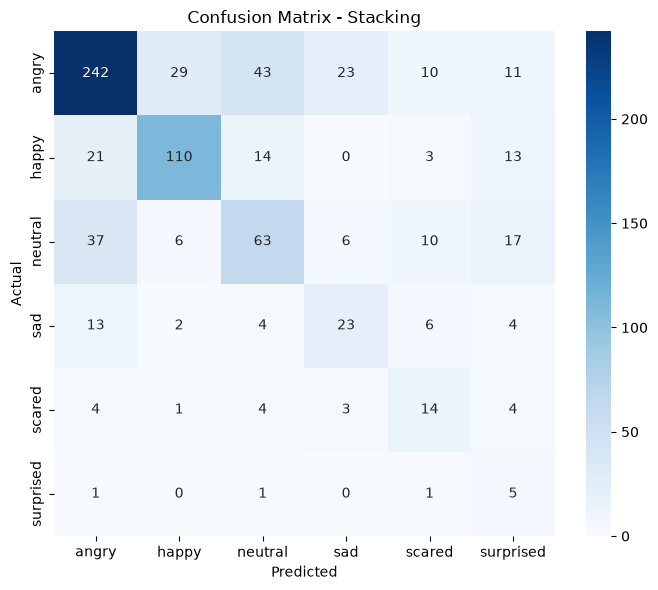

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

print("=== STACKING ENSEMBLE (NB + SVM) ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("F1-macro :", round(f1_score(y_test, y_pred, average="macro"), 4))
print()
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix - Stacking")
plt.tight_layout(); plt.show()

In [15]:
# (Optional) Supporting/ablation table: each base model vs the ensemble
rows = []
for name, p in [("Naive Bayes", p_nb), ("SVM", p_svm)]:
    pr = p.argmax(1)
    rows.append([name, accuracy_score(y_test, pr), f1_score(y_test, pr, average="macro")])
rows.append(["Stacking (NB+SVM)", accuracy_score(y_test, y_pred), f1_score(y_test, y_pred, average="macro")])
pd.DataFrame(rows, columns=["Model", "Accuracy", "F1-macro"]).round(4)

,Model,Accuracy,F1-macro
0,Naive Bayes,0.6310,0.3019
1,SVM,0.6805,0.4705
2,Stacking (NB+SVM),0.6110,0.4779


## 9. Predict new comments

In [16]:
def predict_comment(text):
    c = clean_text(text)
    f = np.hstack([
        nb_full.predict_proba([c]),
        svm_full.predict_proba([c]),
    ])
    prob = meta.predict_proba(f)[0]
    return le.classes_[prob.argmax()], dict(zip(le.classes_, prob.round(3)))

# Example comments (Indonesian, like the dataset)
for s in [
    "IHSG hijau terus, mantap cuan hari ini",
    "IHSG merah lagi, mending cash dulu",
    "Besok IHSG dibuka jam berapa ya?",
]:
    print(s, "->", predict_comment(s))

IHSG hijau terus, mantap cuan hari ini -> ('surprised', {'angry': np.float64(0.119), 'happy': np.float64(0.145), 'neutral': np.float64(0.193), 'sad': np.float64(0.146), 'scared': np.float64(0.193), 'surprised': np.float64(0.204)})
IHSG merah lagi, mending cash dulu -> ('neutral', {'angry': np.float64(0.123), 'happy': np.float64(0.126), 'neutral': np.float64(0.254), 'sad': np.float64(0.101), 'scared': np.float64(0.19), 'surprised': np.float64(0.205)})
Besok IHSG dibuka jam berapa ya? -> ('neutral', {'angry': np.float64(0.036), 'happy': np.float64(0.048), 'neutral': np.float64(0.354), 'sad': np.float64(0.063), 'scared': np.float64(0.242), 'surprised': np.float64(0.256)})
